# CSE558 Data Science — Assignment 1, Question 2
**JL for linear regression**

This notebook implements Q2(a)–Q2(e) using the KDD Cup 1999 data. It prepares the feature matrix and binary normal/attack response, computes the full least-squares baseline, and evaluates CountSketch and Gaussian sketching in terms of regression loss, runtime, and residual norm preservation.

Run the notebook from top to bottom. Fixed random seeds are used for reproducibility. The original-data loss and the compressed/sketched loss are different quantities; the comments below identify which one is being calculated in each experiment. Result tables are exported as CSV files in the notebook's working directory.

### Q2(a) Report Loss(𝐷,𝑦,𝑏) and the time to compute 𝑏.  

## Import libraries and set reproducible random seeds
    NumPy and pandas support numerical operations and result tables. The KDD loader and Min-Max scaler prepare the data, `numpy.linalg.lstsq` solves least-squares systems, Matplotlib/Seaborn create plots, and `time` measures runtime. Both NumPy and Python's `random` module are seeded for reproducibility.

In [1]:
# Core numerical and tabular data manipulation
import numpy as np
import pandas as pd

# KDD Cup 1999 dataset loader
from sklearn.datasets import fetch_kddcup99

# Preprocessing
from sklearn.preprocessing import MinMaxScaler

# Linear regression
from numpy.linalg import lstsq

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Time measurement
import time

# Reproducibility
import random

# Fixed random seeds
SEED = 42

np.random.seed(SEED)
random.seed(SEED)

print("All libraries imported successfully!")

All libraries imported successfully!


## Load the KDD Cup 1999 dataset
    Fetch the default 10% dataset. `X` contains the connection features and `target` contains the original class labels. The feature matrix is prepared in the next cells; the labels are converted into a binary response for regression.

In [2]:
kdd = fetch_kddcup99(
    subset=None,
    as_frame=True
)

X = kdd.data.copy()
target = kdd.target

print("Dataset loaded successfully!")

print("Original data shape:", X.shape)
print("Target shape:", target.shape)

Dataset loaded successfully!
Original data shape: (494021, 41)
Target shape: (494021,)


## One-hot encode categorical features
    Expand `protocol_type`, `service`, and `flag` into numeric indicator columns. This converts categorical values into a representation that can be used by matrix operations and least-squares regression.

In [3]:
categorical_features = [
    'protocol_type',
    'service',
    'flag'
]

X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    dtype=np.float32
)

print("Shape after one-hot encoding:", X_encoded.shape)

Shape after one-hot encoding: (494021, 118)


## Remove constant columns
    Drop any feature that has the same value for every observation. Constant columns do not add explanatory variation and can unnecessarily increase the size of the regression design matrix.

In [4]:
X_encoded = X_encoded.loc[
    :,
    X_encoded.nunique() > 1
]

print("Shape after removing constant columns:", X_encoded.shape)

Shape after removing constant columns: (494021, 116)


## Scale the design matrix D
    Apply Min-Max scaling to every retained feature so that values lie in [0, 1]. Store the resulting design matrix as `float32` to reduce memory usage. This D is used in the full and sketched regression experiments.

In [5]:
scaler = MinMaxScaler()

D = scaler.fit_transform(
    X_encoded
).astype(np.float32)

print("Final D shape:", D.shape)
print("Number of samples:", D.shape[0])
print("Number of features:", D.shape[1])

Final D shape: (494021, 116)
Number of samples: 494021
Number of features: 116


## Construct the binary response y
    Set yᵢ=0 for normal connections and yᵢ=1 for every attack category. The original labels are nominal categories, so their numeric category codes should not be treated as an ordered regression response.

In [6]:
y = (
    kdd.target != b'normal.'
).to_numpy(dtype=float)

print("Target shape:", y.shape)

print("Normal connections:", np.sum(y == 0))
print("Attack connections:", np.sum(y == 1))

print("Unique labels:", np.unique(y))

Target shape: (494021,)
Normal connections: 97278
Attack connections: 396743
Unique labels: [0. 1.]


## Verify the prepared regression data
    Check matrix/vector dimensions, data types, missing-value counts, and the range of D. These checks help confirm that the design matrix and target vector are compatible with the least-squares calculations.

In [7]:
print("Q2 Dataset Verification")
print("-------------------------------")

print("D shape:", D.shape)
print("y shape:", y.shape)

print("D data type:", D.dtype)
print("y data type:", y.dtype)

print("Missing values in D:", np.isnan(D).sum())
print("Missing values in y:", np.isnan(y).sum())

print("Minimum D value:", D.min())
print("Maximum D value:", D.max())

Q2 Dataset Verification
-------------------------------
D shape: (494021, 116)
y shape: (494021,)
D data type: float32
y data type: float64
Missing values in D: 0
Missing values in y: 0
Minimum D value: 0.0
Maximum D value: 1.0


## Q2(a) — Fit full least-squares regression
    Solve minₐ ||Da−y||²₂ using `numpy.linalg.lstsq`. The returned coefficient vector is the full-data least-squares solution. The function also returns the numerical rank and singular values; the timer measures the solve itself.

In [8]:
# ---------------------------------------
# Q2(a): Full Least Squares Regression
# ---------------------------------------

print("Starting Full Least Squares Regression...")

# Start timer
start_time = time.perf_counter()

# Solve least squares problem
b, residuals, rank_D, singular_values = np.linalg.lstsq(
    D,
    y,
    rcond=None
)

# Stop timer
end_time = time.perf_counter()

# Execution time
baseline_regression_time = end_time - start_time

print("\nFull Regression Completed!")
print("--------------------------------")

print("Coefficient vector shape:", b.shape)
print("Rank of D:", rank_D)
print("Execution time:", baseline_regression_time, "seconds")

Starting Full Least Squares Regression...

Full Regression Completed!
--------------------------------
Coefficient vector shape: (116,)
Rank of D: 113
Execution time: 6.111060399998678 seconds


## Q2(a) — Calculate the full-data regression loss
    Use the fitted coefficients to calculate predictions D b. The squared regression loss is the sum of squared residuals over all observations. This is the baseline loss against which every sketched solution is evaluated.

In [9]:
# Calculate predictions
y_pred = D @ b

# Calculate squared regression loss
baseline_loss = np.sum(
    (y_pred - y) ** 2,
    dtype=np.float64
)

print("Full Regression Results")
print("--------------------------------")

print("Regression Loss:", baseline_loss)
print("Regression Time:", baseline_regression_time)

Full Regression Results
--------------------------------
Regression Loss: 2949.788814891839
Regression Time: 6.111060399998678


## Q2(a) — Assemble the baseline result table
    Record n, d, the numerical rank of D, the full-data squared loss, and the measured solve time. These values provide the reference point for Q2(b) and Q2(c).

In [10]:
q2a_results = pd.DataFrame([{
    "Number_of_Samples": D.shape[0],
    "Number_of_Features": D.shape[1],
    "Rank_of_D": rank_D,
    "Full_Regression_Loss": baseline_loss,
    "Execution_Time_Seconds": baseline_regression_time
}])

print(q2a_results.to_string(index=False))

 Number_of_Samples  Number_of_Features  Rank_of_D  Full_Regression_Loss  Execution_Time_Seconds
            494021                 116        113           2949.788815                 6.11106


## Q2(a) — Export baseline results
    Write the Q2(a) result table to CSV for use in the report and for reproducibility.

In [11]:
q2a_results.to_csv(
    "Q2a_Full_Regression_Results.csv",
    index=False
)

print("Q2(a) results saved successfully!")

Q2(a) results saved successfully!


### Q2(b) For each of 𝑚 = 50, 100, 200, 500, 1000, 2000 and 5000, draw 𝑆, compute 𝑎̃, and report Loss(𝐷,𝑦,𝑎̃), its ratio to Loss(𝐷,𝑦,𝑏), and the sketched loss ‖𝑆𝐷𝑎̃ − 𝑆𝑦‖2 2. Repeat this 5 times for each 𝑚, with a fresh 𝑆 each time. Plot the mean ratio against 𝑚 on log–log axes, with the smallest and largest of the 5 ratios as error bars. Describe what happens to the ratio and to the sketched loss below and above 𝑚 = 𝑟𝑎𝑛𝑘(𝐷).

## Helper function — Build a CountSketch of D and y
    Each original row i is assigned uniformly to one of m buckets and receives an independent random sign of −1 or +1. Add the signed row of D to the selected row of SD, and add the signed response to the matching entry of Sy. `numpy.add.at` performs these repeated-index additions without ever constructing the dense m-by-n sketching matrix. The returned pair (SD, Sy) is the sketched regression problem.

In [12]:
def countsketch(D, y, m, rng):

    n, d = D.shape

    # Generate random bucket assignments
    h = rng.integers(
        low=0,
        high=m,
        size=n
    )

    # Generate random signs: -1 or +1
    signs = rng.choice(
        [-1.0, 1.0],
        size=n
    )

    # Initialize sketched data
    SD = np.zeros(
        (m, d),
        dtype=np.float64
    )

    Sy = np.zeros(
        m,
        dtype=np.float64
    )

    # Add signed rows directly to buckets
    np.add.at(
        SD,
        h,
        signs[:, None] * D
    )

    np.add.at(
        Sy,
        h,
        signs * y
    )

    return SD, Sy

## Helper function — Evaluate regression loss on the original data
    Given a coefficient vector, calculate predictions on the original matrix D and return the sum of squared differences from y. Evaluating on the original data is essential: it measures how well a sketched solution generalises back to the full regression objective.

In [13]:
def calculate_regression_loss(D, y, coefficients):

    predictions = D @ coefficients

    loss = np.sum(
        (predictions - y) ** 2,
        dtype=np.float64
    )

    return loss

## Q2(b) — Run CountSketch regression over dimensions and repetitions
    For each prescribed m, generate five independent CountSketches, solve the sketched least-squares problem, and evaluate the resulting coefficients on the original D and y. Record the original-data loss, its ratio to the full-data baseline, the sketched residual loss, and the sketch rank. Fresh seeded random generators make each repetition independent and reproducible.

In [14]:
# Sketch dimensions
m_values_q2 = [
    50, 100, 200, 500, 1000, 2000, 5000
]

# Number of repetitions
n_repeats_q2 = 5

# Store experimental results
results_q2b = []

for m in m_values_q2:

    print(f"\nRunning experiments for m = {m}")

    for rep in range(n_repeats_q2):

        print(f"Repetition {rep + 1}/5")

        # Independent random generator
        rng = np.random.default_rng(
            SEED + m * 100 + rep
        )

        # --------------------------------
        # Step 1: Generate CountSketch
        # --------------------------------

        SD, Sy = countsketch(
            D,
            y,
            m,
            rng
        )

        # --------------------------------
        # Step 2: Solve sketched regression
        # --------------------------------

        a_tilde, sketch_residuals, sketch_rank, sketch_singular_values = (
            np.linalg.lstsq(
                SD,
                Sy,
                rcond=None
            )
        )

        # --------------------------------
        # Step 3: Original dataset loss
        # --------------------------------

        original_loss = calculate_regression_loss(
            D,
            y,
            a_tilde
        )

        # --------------------------------
        # Step 4: Loss ratio
        # --------------------------------

        loss_ratio = (
            original_loss / baseline_loss
        )

        # --------------------------------
        # Step 5: Sketched loss
        # --------------------------------

        sketched_predictions = SD @ a_tilde

        sketched_loss = np.sum(
            (sketched_predictions - Sy) ** 2,
            dtype=np.float64
        )

        # --------------------------------
        # Step 6: Store results
        # --------------------------------

        results_q2b.append({
            "m": m,
            "repetition": rep + 1,
            "Original_Loss": original_loss,
            "Loss_Ratio": loss_ratio,
            "Sketched_Loss": sketched_loss,
            "Sketch_Rank": sketch_rank
        })

        print("Original loss:", original_loss)
        print("Loss ratio:", loss_ratio)
        print("Sketched loss:", sketched_loss)

        del SD, Sy, a_tilde


Running experiments for m = 50
Repetition 1/5
Original loss: 10003.085449271555
Loss ratio: 3.3911191875064253
Sketched loss: 1.833188300925833e-24
Repetition 2/5
Original loss: 9141.449248992361
Loss ratio: 3.0990182086399813
Sketched loss: 1.7459063243464192e-23
Repetition 3/5
Original loss: 11143.875398145232
Loss ratio: 3.7778553304853615
Sketched loss: 2.1806900099304196e-24
Repetition 4/5
Original loss: 13050.554190247745
Loss ratio: 4.424233397442818
Sketched loss: 1.5350419111146702e-23
Repetition 5/5
Original loss: 11590.14036757435
Loss ratio: 3.929142421675136
Sketched loss: 1.1390807528036734e-23

Running experiments for m = 100
Repetition 1/5
Original loss: 73503.71938642325
Loss ratio: 24.91829890171932
Sketched loss: 3.710271268086969e-23
Repetition 2/5
Original loss: 51297.237471751614
Loss ratio: 17.39013898648624
Sketched loss: 9.422606195941914e-23
Repetition 3/5
Original loss: 38715.63746497127
Loss ratio: 13.124884489871818
Sketched loss: 6.8254893922996e-23
Repet

## Q2(b) — Summarise loss and ratio results
    Group the five runs for each m. Report mean/minimum/maximum original-loss ratios and the mean original and sketched losses. The ratio compares the sketched solution with the full-data optimum; the sketched loss is measured only on the compressed system and should not be confused with original-data loss.

In [15]:
results_q2b_df = pd.DataFrame(results_q2b)

summary_q2b = results_q2b_df.groupby("m").agg(
    Mean_Ratio=("Loss_Ratio", "mean"),
    Minimum_Ratio=("Loss_Ratio", "min"),
    Maximum_Ratio=("Loss_Ratio", "max"),
    Mean_Original_Loss=("Original_Loss", "mean"),
    Mean_Sketched_Loss=("Sketched_Loss", "mean")
).reset_index()

print("\nQ2(b) Summary Results")
print("--------------------------------")

print(
    summary_q2b.to_string(index=False)
)


Q2(b) Summary Results
--------------------------------
   m  Mean_Ratio  Minimum_Ratio  Maximum_Ratio  Mean_Original_Loss  Mean_Sketched_Loss
  50    3.724274       3.099018       4.424233        10985.820931        9.642834e-24
 100   15.300822       8.937157      24.918299        45134.193982        4.521068e-23
 200    2.189437       2.069083       2.437447         6458.376200        1.157888e+03
 500    1.308488       1.267666       1.389591         3859.762778        2.263586e+03
1000    1.129316       1.120580       1.151407         3331.244291        2.619847e+03
2000    1.058080       1.050920       1.061842         3121.113778        2.801201e+03
5000    1.022984       1.018155       1.029381         3017.585949        2.893952e+03


## Q2(b) — Plot original-data loss ratio
    Plot the mean loss ratio on logarithmic x and y axes. Error bars show the minimum and maximum ratios across five runs. The horizontal line at 1 is the full-regression baseline. This plot is used to discuss the effect of sketch dimension and the behaviour below versus above rank(D).

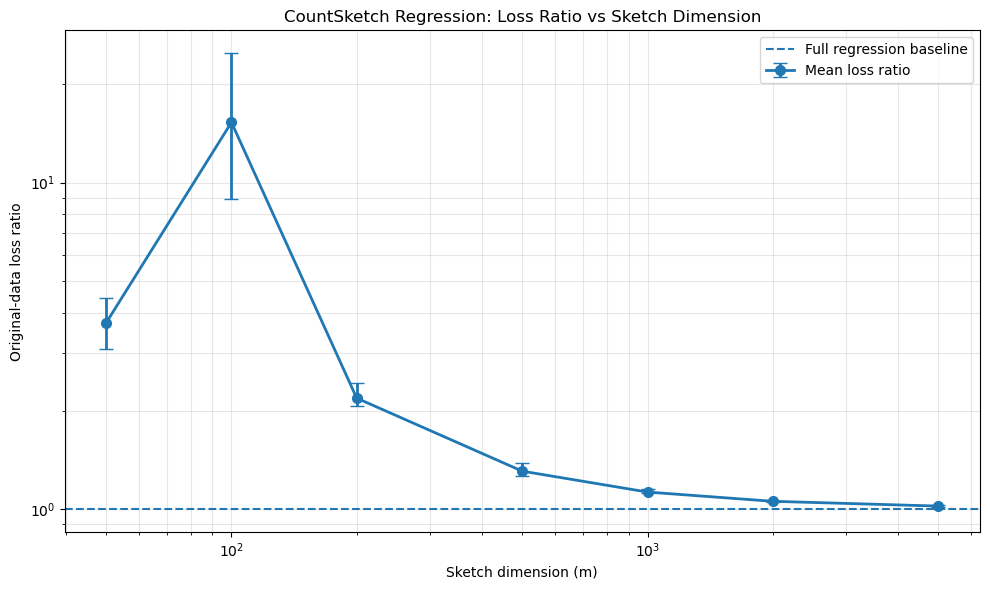

In [16]:
mean_ratio = summary_q2b["Mean_Ratio"].values

lower_error = (
    mean_ratio -
    summary_q2b["Minimum_Ratio"].values
)

upper_error = (
    summary_q2b["Maximum_Ratio"].values -
    mean_ratio
)

plt.figure(figsize=(10, 6))

plt.errorbar(
    summary_q2b["m"],
    mean_ratio,
    yerr=[lower_error, upper_error],
    fmt='o-',
    capsize=5,
    linewidth=2,
    markersize=7,
    label="Mean loss ratio"
)

plt.axhline(
    y=1,
    linestyle='--',
    label="Full regression baseline"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Sketch dimension (m)")
plt.ylabel("Original-data loss ratio")

plt.title(
    "CountSketch Regression: Loss Ratio vs Sketch Dimension"
)

plt.legend()
plt.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

## Q2(b) — Export individual and summary results
    Save all five observations per sketch dimension and the aggregated summary table.

In [17]:
results_q2b_df.to_csv(
    "Q2b_Individual_Results.csv",
    index=False
)

summary_q2b.to_csv(
    "Q2b_Summary.csv",
    index=False
)

print("Q2(b) results saved successfully!")

Q2(b) results saved successfully!


### Q2(c) For each 𝑚, report the time to draw 𝑆, form 𝑆𝐷 and 𝑆𝑦 and compute 𝑎̃, averaged over the 5 runs in (b), and compare it with the time to compute 𝑏 in (a).

## Q2(c) — Measure CountSketch pipeline time
    For each m and five repetitions, time the creation of the CountSketch and construction of SD and Sy, followed by solving the sketched least-squares problem. The random generator is initialized before the timer so seed setup itself is excluded. These measurements are compared with the full regression solve time from Q2(a).

In [18]:
timing_results_q2c = []

for m in m_values_q2:

    print(f"\nTiming experiments for m = {m}")

    for rep in range(n_repeats_q2):

        # Create random generator before timing
        rng = np.random.default_rng(
            SEED + m * 100 + rep
        )

        # Start timer
        start_time = time.perf_counter()

        # Generate CountSketch and construct SD, Sy
        SD, Sy = countsketch(
            D,
            y,
            m,
            rng
        )

        # Solve sketched least-squares problem
        a_tilde, _, sketch_rank, _ = np.linalg.lstsq(
            SD,
            Sy,
            rcond=None
        )

        # Stop timer
        end_time = time.perf_counter()

        elapsed_time = end_time - start_time

        timing_results_q2c.append({
            "m": m,
            "repetition": rep + 1,
            "time_seconds": elapsed_time
        })

        print(
            f"Repetition {rep + 1}: "
            f"{elapsed_time:.6f} seconds"
        )

        del SD, Sy, a_tilde


Timing experiments for m = 50
Repetition 1: 1.851053 seconds
Repetition 2: 1.771282 seconds
Repetition 3: 1.627272 seconds
Repetition 4: 1.846706 seconds
Repetition 5: 2.004616 seconds

Timing experiments for m = 100
Repetition 1: 1.932557 seconds
Repetition 2: 2.084242 seconds
Repetition 3: 1.859875 seconds
Repetition 4: 1.920055 seconds
Repetition 5: 1.783492 seconds

Timing experiments for m = 200
Repetition 1: 1.906385 seconds
Repetition 2: 1.778608 seconds
Repetition 3: 1.780606 seconds
Repetition 4: 1.887627 seconds
Repetition 5: 1.771055 seconds

Timing experiments for m = 500
Repetition 1: 1.879948 seconds
Repetition 2: 1.913686 seconds
Repetition 3: 1.862281 seconds
Repetition 4: 1.845874 seconds
Repetition 5: 1.769722 seconds

Timing experiments for m = 1000
Repetition 1: 1.901203 seconds
Repetition 2: 1.864412 seconds
Repetition 3: 1.794396 seconds
Repetition 4: 1.817842 seconds
Repetition 5: 1.878989 seconds

Timing experiments for m = 2000
Repetition 1: 1.913647 seconds
R

## Q2(c) — Summarise timing measurements
    Calculate mean, minimum, and maximum pipeline time for every m. The mean is used for the timing plot, while the range indicates run-to-run variability.

In [19]:
timing_q2c_df = pd.DataFrame(
    timing_results_q2c
)

timing_summary_q2c = timing_q2c_df.groupby("m").agg(
    Mean_Time=("time_seconds", "mean"),
    Minimum_Time=("time_seconds", "min"),
    Maximum_Time=("time_seconds", "max")
).reset_index()

print("\nQ2(c) Timing Summary")
print("--------------------------------")

print(
    timing_summary_q2c.to_string(index=False)
)


Q2(c) Timing Summary
--------------------------------
   m  Mean_Time  Minimum_Time  Maximum_Time
  50   1.820186      1.627272      2.004616
 100   1.916044      1.783492      2.084242
 200   1.824856      1.771055      1.906385
 500   1.854302      1.769722      1.913686
1000   1.851368      1.794396      1.901203
2000   1.853612      1.772847      1.934994
5000   1.861890      1.830402      1.903025


## Q2(c) — Plot full versus sketched regression time
    Plot average CountSketch pipeline time against m and add the full-data regression time as a horizontal reference. The x-axis is logarithmic because the tested sketch dimensions span two orders of magnitude.

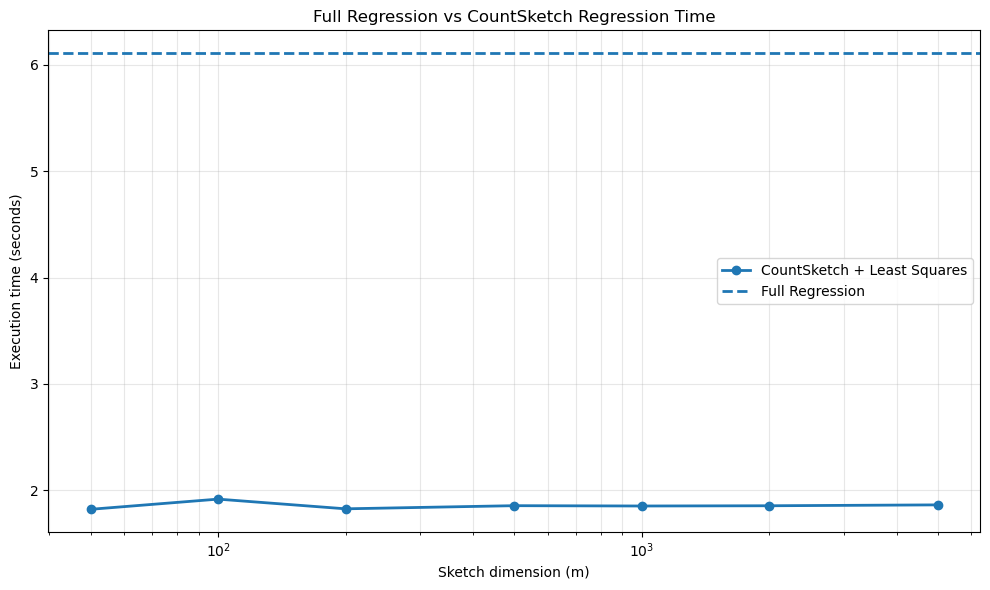

In [20]:
plt.figure(figsize=(10, 6))

plt.plot(
    timing_summary_q2c["m"],
    timing_summary_q2c["Mean_Time"],
    marker="o",
    linewidth=2,
    label="CountSketch + Least Squares"
)

plt.axhline(
    y=baseline_regression_time,
    linestyle="--",
    linewidth=2,
    label="Full Regression"
)

plt.xscale("log")

plt.xlabel("Sketch dimension (m)")
plt.ylabel("Execution time (seconds)")

plt.title(
    "Full Regression vs CountSketch Regression Time"
)

plt.legend()
plt.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

## Q2(c) — Export timing results
    Save the per-run timings and their grouped summary to CSV files.

In [21]:
timing_q2c_df.to_csv(
    "Q2c_Individual_Timings.csv",
    index=False
)

timing_summary_q2c.to_csv(
    "Q2c_Timing_Summary.csv",
    index=False
)

print("Q2(c) timing results saved successfully!")

Q2(c) timing results saved successfully!


### Q2(d) Let 𝑣 = 𝐷𝑏−𝑦 be the residual of the full solution. For 𝑚 ∈ {50,500,5000}, draw 100 independent CountSketches 𝑆 and compute ‖𝑆𝑣‖2 2/‖𝑣‖2 2. For each 𝑚, plot a histogram and report the mean and standard deviation. How does the spread change with 𝑚?

## Q2(d) — Compute the full-solution residual
    Form v = D b − y using the full-data least-squares coefficients. Its squared norm equals the baseline regression loss (up to floating-point precision). This residual vector is the object whose norm preservation is tested under CountSketch.

In [22]:
# Calculate full regression residual
v = D @ b - y

# Calculate original residual squared norm
original_residual_norm = np.sum(
    v ** 2,
    dtype=np.float64
)

print("Residual vector shape:", v.shape)

print(
    "Original residual squared norm:",
    original_residual_norm
)

print("Baseline regression loss:", baseline_loss)

Residual vector shape: (494021,)
Original residual squared norm: 2949.788814891839
Baseline regression loss: 2949.788814891839


## Helper function — Apply CountSketch to a residual vector
    Assign each residual entry to a random bucket with an independent random sign, accumulating into an m-dimensional vector Sv. This is the vector-only version of the CountSketch construction used in Q2(b).

In [23]:
def sketch_residual(v, m, rng):

    n = len(v)

    # Generate random bucket assignments
    h = rng.integers(
        low=0,
        high=m,
        size=n
    )

    # Generate random signs
    signs = rng.choice(
        [-1.0, 1.0],
        size=n
    )

    # Initialize sketched residual
    Sv = np.zeros(
        m,
        dtype=np.float64
    )

    # Add signed residuals to buckets
    np.add.at(
        Sv,
        h,
        signs * v
    )

    return Sv

## Q2(d) — Repeat residual norm preservation experiments
    For each m in {50, 500, 5000}, draw 100 independent CountSketches and calculate ||Sv||²₂ / ||v||²₂. A ratio near 1 indicates preservation of the squared residual norm; the 100 repetitions reveal the distribution and its variability.

In [24]:
# Sketch dimensions required by assignment
m_values_q2d = [50, 500, 5000]

# Number of independent sketches
N_DRAWS = 100

# Store experimental results
results_q2d = []

for m in m_values_q2d:

    print(f"\nRunning Q2(d) for m = {m}")

    for rep in range(N_DRAWS):

        # Independent random generator
        rng = np.random.default_rng(
            20000 + m * 100 + rep
        )

        # Generate sketched residual
        Sv = sketch_residual(
            v,
            m,
            rng
        )

        # Calculate residual norm ratio
        ratio = (
            np.sum(Sv ** 2) /
            original_residual_norm
        )

        results_q2d.append({
            "m": m,
            "repetition": rep + 1,
            "Residual_Norm_Ratio": ratio
        })

    print("Completed 100 experiments")


Running Q2(d) for m = 50
Completed 100 experiments

Running Q2(d) for m = 500
Completed 100 experiments

Running Q2(d) for m = 5000
Completed 100 experiments


## Q2(d) — Summarise residual norm ratios
    Calculate the mean, sample standard deviation, minimum, and maximum ratio for each sketch dimension. Compare the standard deviations to assess whether the spread narrows as m increases.

In [25]:
results_q2d_df = pd.DataFrame(
    results_q2d
)

summary_q2d = results_q2d_df.groupby("m").agg(
    Mean_Ratio=("Residual_Norm_Ratio", "mean"),
    Standard_Deviation=("Residual_Norm_Ratio", "std"),
    Minimum_Ratio=("Residual_Norm_Ratio", "min"),
    Maximum_Ratio=("Residual_Norm_Ratio", "max")
).reset_index()

print("\nQ2(d) Summary")
print("--------------------------------")

print(
    summary_q2d.to_string(index=False)
)


Q2(d) Summary
--------------------------------
   m  Mean_Ratio  Standard_Deviation  Minimum_Ratio  Maximum_Ratio
  50    1.003914            0.230215       0.551231       1.807681
 500    1.015194            0.064129       0.865631       1.185118
5000    0.996482            0.019337       0.924779       1.042744


## Q2(d) — Plot residual norm histograms
    Show one histogram for each required m. The dashed line marks the ideal ratio 1 and the dash-dot line marks the empirical mean. A narrower distribution concentrated near 1 indicates more reliable norm preservation.

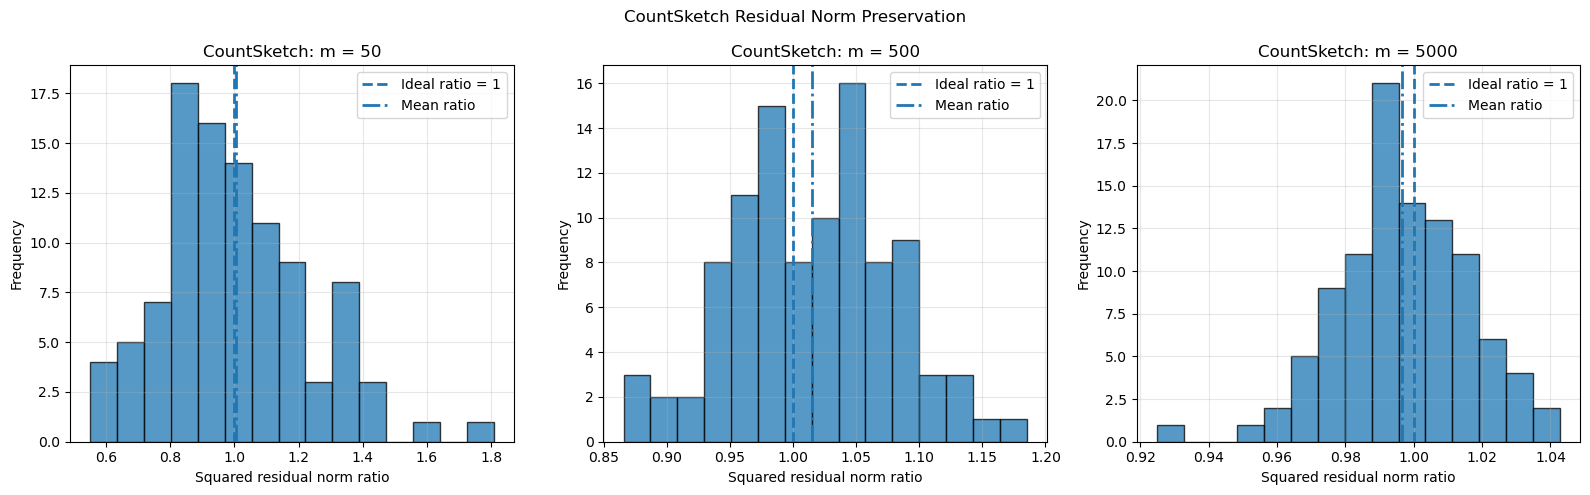

In [26]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

for i, m in enumerate(m_values_q2d):

    ratios = results_q2d_df.loc[
        results_q2d_df["m"] == m,
        "Residual_Norm_Ratio"
    ]

    axes[i].hist(
        ratios,
        bins=15,
        edgecolor="black",
        alpha=0.75
    )

    axes[i].axvline(
        1,
        linestyle="--",
        linewidth=2,
        label="Ideal ratio = 1"
    )

    axes[i].axvline(
        ratios.mean(),
        linestyle="-.",
        linewidth=2,
        label="Mean ratio"
    )

    axes[i].set_title(f"CountSketch: m = {m}")

    axes[i].set_xlabel(
        "Squared residual norm ratio"
    )

    axes[i].set_ylabel("Frequency")

    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.suptitle(
    "CountSketch Residual Norm Preservation"
)

plt.tight_layout()
plt.show()

## Q2(d) — Export residual norm results
    Save all 100 ratios per dimension and the corresponding summary statistics.

In [27]:
results_q2d_df.to_csv(
    "Q2d_Individual_Results.csv",
    index=False
)

summary_q2d.to_csv(
    "Q2d_Summary.csv",
    index=False
)

print("Q2(d) results saved successfully!")

Q2(d) results saved successfully!


### Q2(e) Select 50,000 rows uniformly at random without replacement, once, using a fixed random seed. Use this same subset for both sketching methods and all five repetitions. Draw a fresh sketch in each repetition.. Let 𝐷′ hold these rows and 𝑦′ the matching entries of 𝑦, and let 𝑏′ minimise Loss(𝐷′,𝑦′,𝑎). For 𝑚 =500, sketch (𝐷′,𝑦′) in two ways: (i) with a CountSketch, and (ii) with a dense ∈ℝ𝑚×50000 with i.i.d. 𝑁(0,1/𝑚) entries. For each, solve the sketched problem for 𝑎̃, and report the time to draw 𝑆 and form 𝑆𝐷′ and 𝑆𝑦′, and the ratio Loss(𝐷′,𝑦′, 𝑎̃)/Loss(𝐷′,𝑦′,𝑏′), each averaged over 5 repetitions. Which sketch would you use on the full 𝐷? 

## Q2(e) — Select one fixed 50,000-row subset
    Select 50,000 observations uniformly without replacement using a fixed seed. Both CountSketch and Gaussian sketching use exactly this same subset, so the comparison is not confounded by different sampled rows.

In [28]:
# Fixed random seed for subset selection
SUBSET_SEED = 2026

N_SUBSET = 50000

rng_subset = np.random.default_rng(
    SUBSET_SEED
)

# Select indices without replacement
subset_indices = rng_subset.choice(
    D.shape[0],
    size=N_SUBSET,
    replace=False
)

# Construct subset
D_subset = D[subset_indices].copy()

y_subset = y[subset_indices].copy()

print("Subset dimensions")
print("----------------------------")

print("D_subset shape:", D_subset.shape)
print("y_subset shape:", y_subset.shape)

print("Unique selected indices:", len(np.unique(subset_indices)))

Subset dimensions
----------------------------
D_subset shape: (50000, 116)
y_subset shape: (50000,)
Unique selected indices: 50000


## Q2(e) — Fit the subset baseline regression
    Solve least squares on the selected subset and measure its runtime and squared loss. This subset-specific optimum is the denominator for the loss ratios in Q2(e); it is not the full-dataset baseline from Q2(a).

In [29]:
print("Calculating subset baseline regression...")

start_time = time.perf_counter()

b_subset, residuals_subset, rank_subset, singular_values_subset = (
    np.linalg.lstsq(
        D_subset,
        y_subset,
        rcond=None
    )
)

end_time = time.perf_counter()

subset_baseline_time = end_time - start_time

# Calculate baseline subset loss
subset_baseline_loss = np.sum(
    (D_subset @ b_subset - y_subset) ** 2,
    dtype=np.float64
)

print("\nSubset baseline results")
print("----------------------------")

print("Rank of D_subset:", rank_subset)
print("Subset baseline loss:", subset_baseline_loss)
print("Subset regression time:", subset_baseline_time)

Calculating subset baseline regression...

Subset baseline results
----------------------------
Rank of D_subset: 108
Subset baseline loss: 305.8412733700454
Subset regression time: 0.23675709999952232


## Q2(e) — Set common sketching parameters
    Fix the sketch dimension at m=500 and use five repetitions for each method. The same subset, sketch dimension, and repetition count are used for a fair method comparison.

In [30]:
# Sketch dimension
M_Q2E = 500

# Number of repetitions
N_REPEATS_Q2E = 5

# Store results
results_q2e = []

## Q2(e)(i) — CountSketch on the subset
    For each repetition, generate a fresh sparse CountSketch and construct SD and Sy. The timer measures sketch generation and construction. Solve the sketched least-squares problem, evaluate its loss on the original 50,000-row subset, and divide by the subset baseline loss.

In [31]:
for rep in range(N_REPEATS_Q2E):

    print(f"\nCountSketch repetition {rep + 1}/5")

    rng = np.random.default_rng(
        30000 + rep
    )

    # Start timer
    start_time = time.perf_counter()

    # Construct CountSketch
    SD_count, Sy_count = countsketch(
        D_subset,
        y_subset,
        M_Q2E,
        rng
    )

    # Stop timer
    end_time = time.perf_counter()

    count_time = end_time - start_time

    # Solve sketched regression
    a_count, _, rank_count, _ = np.linalg.lstsq(
        SD_count,
        Sy_count,
        rcond=None
    )

    # Calculate loss on original subset
    loss_count = np.sum(
        (D_subset @ a_count - y_subset) ** 2,
        dtype=np.float64
    )

    # Calculate loss ratio
    ratio_count = loss_count / subset_baseline_loss

    results_q2e.append({
        "Method": "CountSketch",
        "Repetition": rep + 1,
        "Sketch_Time": count_time,
        "Original_Loss": loss_count,
        "Loss_Ratio": ratio_count,
        "Sketch_Rank": rank_count
    })

    print("Sketch time:", count_time)
    print("Original loss:", loss_count)
    print("Loss ratio:", ratio_count)

    del SD_count, Sy_count, a_count


CountSketch repetition 1/5
Sketch time: 0.13463010000123177
Original loss: 403.2468940514633
Loss ratio: 1.3184842242124863

CountSketch repetition 2/5
Sketch time: 0.16191650000109803
Original loss: 403.9305039603669
Loss ratio: 1.3207194029421945

CountSketch repetition 3/5
Sketch time: 0.14235570000164444
Original loss: 409.84996175667095
Loss ratio: 1.3400740758124645

CountSketch repetition 4/5
Sketch time: 0.15139690000069095
Original loss: 379.2127225927021
Loss ratio: 1.2399004176714978

CountSketch repetition 5/5
Sketch time: 0.1521498000001884
Original loss: 403.7873942597738
Loss ratio: 1.3202514814644417


## Q2(e)(ii) — Dense Gaussian sketch on the subset
    Generate a dense Gaussian matrix with entries distributed as N(0,1/m), then multiply it by the subset design matrix and response vector. Time sketch generation and both matrix multiplications. Solve the compressed least-squares problem and evaluate the coefficients on the original subset, using the same loss-ratio definition as CountSketch.

In [32]:
for rep in range(N_REPEATS_Q2E):

    print(f"\nGaussian sketch repetition {rep + 1}/5")

    rng = np.random.default_rng(
        40000 + rep
    )

    # Start timer
    start_time = time.perf_counter()

    # Generate dense Gaussian matrix
    S_gaussian = rng.standard_normal(
        size=(M_Q2E, N_SUBSET),
        dtype=np.float32
    )

    # Scale to N(0, 1/m)
    S_gaussian *= np.float32(
        1 / np.sqrt(M_Q2E)
    )

    # Construct sketched data
    SD_gaussian = S_gaussian @ D_subset

    # Construct sketched target
    Sy_gaussian = S_gaussian @ y_subset

    # Stop timer
    end_time = time.perf_counter()

    gaussian_time = end_time - start_time

    # Solve sketched regression
    a_gaussian, _, rank_gaussian, _ = np.linalg.lstsq(
        SD_gaussian,
        Sy_gaussian,
        rcond=None
    )

    # Calculate original subset loss
    loss_gaussian = np.sum(
        (D_subset @ a_gaussian - y_subset) ** 2,
        dtype=np.float64
    )

    # Calculate loss ratio
    ratio_gaussian = (
        loss_gaussian / subset_baseline_loss
    )

    results_q2e.append({
        "Method": "Gaussian",
        "Repetition": rep + 1,
        "Sketch_Time": gaussian_time,
        "Original_Loss": loss_gaussian,
        "Loss_Ratio": ratio_gaussian,
        "Sketch_Rank": rank_gaussian
    })

    print("Sketch time:", gaussian_time)
    print("Original loss:", loss_gaussian)
    print("Loss ratio:", ratio_gaussian)

    del S_gaussian, SD_gaussian, Sy_gaussian, a_gaussian


Gaussian sketch repetition 1/5
Sketch time: 0.6617604999992182
Original loss: 367.2219317335317
Loss ratio: 1.200694489946163

Gaussian sketch repetition 2/5
Sketch time: 0.6338015000001178
Original loss: 394.2695411225215
Loss ratio: 1.2891312437268216

Gaussian sketch repetition 3/5
Sketch time: 0.5519051000010222
Original loss: 375.42768560807565
Loss ratio: 1.2275245962432146

Gaussian sketch repetition 4/5
Sketch time: 0.5885864999945625
Original loss: 385.1407120884534
Loss ratio: 1.259282986382487

Gaussian sketch repetition 5/5
Sketch time: 0.5427328000005218
Original loss: 378.7480609661913
Loss ratio: 1.2383811275462944


## Q2(e) — Aggregate the two methods
    Group the five repetitions by sketching method. Compare average/minimum/maximum sketch construction time, mean original-subset loss, and mean/minimum/maximum loss ratio.

In [33]:
results_q2e_df = pd.DataFrame(results_q2e)

summary_q2e = results_q2e_df.groupby("Method").agg(
    Mean_Time=("Sketch_Time", "mean"),
    Minimum_Time=("Sketch_Time", "min"),
    Maximum_Time=("Sketch_Time", "max"),
    Mean_Original_Loss=("Original_Loss", "mean"),
    Mean_Loss_Ratio=("Loss_Ratio", "mean"),
    Minimum_Ratio=("Loss_Ratio", "min"),
    Maximum_Ratio=("Loss_Ratio", "max")
).reset_index()

print("\nQ2(e) Comparison Results")
print("--------------------------------")

print(
    summary_q2e.to_string(index=False)
)


Q2(e) Comparison Results
--------------------------------
     Method  Mean_Time  Minimum_Time  Maximum_Time  Mean_Original_Loss  Mean_Loss_Ratio  Minimum_Ratio  Maximum_Ratio
CountSketch   0.148490      0.134630      0.161917          400.005495         1.307886       1.239900       1.340074
   Gaussian   0.595757      0.542733      0.661760          380.161586         1.243003       1.200694       1.289131


## Q2(e) — Plot time and loss-ratio comparison
    The left panel compares average sketch construction times; the right panel compares average original-subset loss ratios. The ideal ratio of 1 is shown for reference. Consider both speed and regression quality when choosing a method.

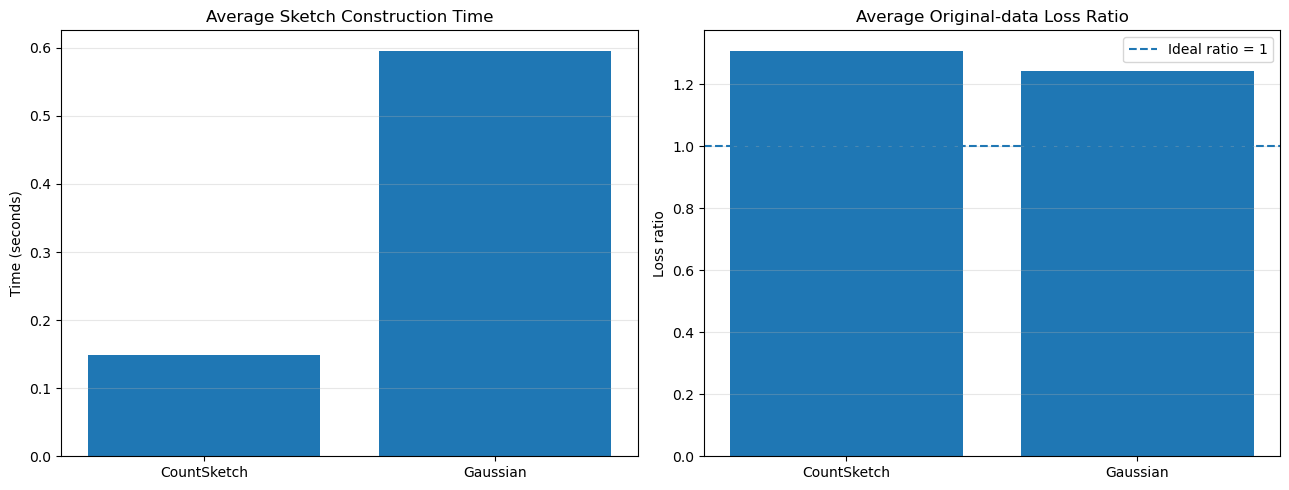

In [34]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

# Execution time comparison
axes[0].bar(
    summary_q2e["Method"],
    summary_q2e["Mean_Time"]
)

axes[0].set_title("Average Sketch Construction Time")
axes[0].set_ylabel("Time (seconds)")
axes[0].grid(axis="y", alpha=0.3)

# Loss ratio comparison
axes[1].bar(
    summary_q2e["Method"],
    summary_q2e["Mean_Loss_Ratio"]
)

axes[1].axhline(
    1,
    linestyle="--",
    label="Ideal ratio = 1"
)

axes[1].set_title("Average Original-data Loss Ratio")
axes[1].set_ylabel("Loss ratio")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Q2(e) — Export comparison results
    Save the five individual measurements per method and the final comparison summary as CSV files.

In [35]:
results_q2e_df.to_csv(
    "Q2e_Individual_Results.csv",
    index=False
)

summary_q2e.to_csv(
    "Q2e_Comparison_Summary.csv",
    index=False
)

print("Q2(e) results saved successfully!")

Q2(e) results saved successfully!
